# Model Evaluation 
### SALSABILA AURELIA OKTANIOPUTRI TP078641

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 5)

# ── Load forecast results (saved from Phase 3) ────────────────────────────
sarima_results  = pd.read_csv('data/model_sarima_results.csv',  parse_dates=['ds'])
prophet_results = pd.read_csv('data/model_prophet_results.csv', parse_dates=['ds'])

# ── Load cleaned weekly series (for plotting full history) ────────────────
df_weekly_clean = pd.read_csv('data/df_weekly_clean.csv', parse_dates=['ds'])

# ── Quick sanity check ────────────────────────────────────────────────────
print(f"SARIMA results  : {sarima_results.shape}")
print(f"Prophet results : {prophet_results.shape}")
print(f"Weekly clean    : {df_weekly_clean.shape}")
print(f"\nSARIMA columns  : {sarima_results.columns.tolist()}")
print(f"Prophet columns : {prophet_results.columns.tolist()}")
print(f"\nTest period: {sarima_results['ds'].min().date()} to {sarima_results['ds'].max().date()}")
print(f"\nAny nulls in SARIMA results  : {sarima_results.isnull().sum().sum()}")
print(f"Any nulls in Prophet results : {prophet_results.isnull().sum().sum()}")

SARIMA results  : (42, 5)
Prophet results : (42, 7)
Weekly clean    : (209, 2)

SARIMA columns  : ['ds', 'actual', 'predicted', 'lower_ci', 'upper_ci']
Prophet columns : ['ds', 'actual', 'yhat', 'yhat_lower', 'yhat_upper', 'trend', 'seasonal']

Test period: 2023-03-19 to 2023-12-31

Any nulls in SARIMA results  : 0
Any nulls in Prophet results : 0


#### 1) POINT FORECAST EVAL

In [2]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def mape(actual, predicted):
    actual, predicted = np.array(actual), np.array(predicted)
    return np.mean(np.abs((actual - predicted) / actual)) * 100

# SARIMA metrics
sarima_mae  = mean_absolute_error(sarima_results['actual'], sarima_results['predicted'])
sarima_rmse = np.sqrt(mean_squared_error(sarima_results['actual'], sarima_results['predicted']))
sarima_mape = mape(sarima_results['actual'], sarima_results['predicted'])

# Prophet metrics
prophet_mae  = mean_absolute_error(prophet_results['actual'], prophet_results['yhat'])
prophet_rmse = np.sqrt(mean_squared_error(prophet_results['actual'], prophet_results['yhat']))
prophet_mape = mape(prophet_results['actual'], prophet_results['yhat'])

print("─── SARIMA ───")
print(f"MAE  : {sarima_mae:.2f} units")
print(f"RMSE : {sarima_rmse:.2f} units")
print(f"MAPE : {sarima_mape:.2f}%")

print("\n─── Prophet ───")
print(f"MAE  : {prophet_mae:.2f} units")
print(f"RMSE : {prophet_rmse:.2f} units")
print(f"MAPE : {prophet_mape:.2f}%")

─── SARIMA ───
MAE  : 661.50 units
RMSE : 743.29 units
MAPE : 34.64%

─── Prophet ───
MAE  : 185.74 units
RMSE : 236.43 units
MAPE : 9.85%


In [3]:
lowest_week = sarima_results.loc[sarima_results['actual'].idxmin()]
print(f"Lowest demand week: {lowest_week['ds'].date()}, actual={lowest_week['actual']}")
print("If this value is very small, double-check it isn't inflating MAPE disproportionately.")

Lowest demand week: 2023-04-09, actual=975.0
If this value is very small, double-check it isn't inflating MAPE disproportionately.


#### 2) PROBABILISTIC EVAL

In [4]:
def coverage_rate(actual, lower, upper):
    actual, lower, upper = np.array(actual), np.array(lower), np.array(upper)
    inside = (actual >= lower) & (actual <= upper)
    return np.mean(inside) * 100

def interval_width(lower, upper):
    return np.mean(np.array(upper) - np.array(lower))

def winkler_score(actual, lower, upper, alpha=0.05):
    actual, lower, upper = np.array(actual), np.array(lower), np.array(upper)
    width = upper - lower
    score = width.copy()
    below = actual < lower
    above = actual > upper
    score[below] += (2/alpha) * (lower[below] - actual[below])
    score[above] += (2/alpha) * (actual[above] - upper[above])
    return np.mean(score)

# SARIMA
sarima_coverage = coverage_rate(sarima_results['actual'], sarima_results['lower_ci'], sarima_results['upper_ci'])
sarima_width     = interval_width(sarima_results['lower_ci'], sarima_results['upper_ci'])
sarima_winkler    = winkler_score(sarima_results['actual'], sarima_results['lower_ci'], sarima_results['upper_ci'])

# Prophet
prophet_coverage = coverage_rate(prophet_results['actual'], prophet_results['yhat_lower'], prophet_results['yhat_upper'])
prophet_width     = interval_width(prophet_results['yhat_lower'], prophet_results['yhat_upper'])
prophet_winkler    = winkler_score(prophet_results['actual'], prophet_results['yhat_lower'], prophet_results['yhat_upper'])

print("─── SARIMA (95% interval) ───")
print(f"Coverage Rate / PICP : {sarima_coverage:.1f}%  (target ≈ 95%)")
print(f"Interval Width       : {sarima_width:.2f} units")
print(f"Winkler Score        : {sarima_winkler:.2f}")

print("\n─── Prophet (95% interval) ───")
print(f"Coverage Rate / PICP : {prophet_coverage:.1f}%  (target ≈ 95%)")
print(f"Interval Width       : {prophet_width:.2f} units")
print(f"Winkler Score        : {prophet_winkler:.2f}")

─── SARIMA (95% interval) ───
Coverage Rate / PICP : 97.6%  (target ≈ 95%)
Interval Width       : 3437.36 units
Winkler Score        : 3790.97

─── Prophet (95% interval) ───
Coverage Rate / PICP : 90.5%  (target ≈ 95%)
Interval Width       : 731.91 units
Winkler Score        : 1296.03


In [6]:

pip install properscoring


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: C:\Users\asus\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [7]:
# pip install properscoring --break-system-packages
import properscoring as ps

# Approximate each forecast as Gaussian using point forecast + interval-derived std
def approx_crps(actual, point_pred, lower, upper):
    std_est = (np.array(upper) - np.array(lower)) / (2 * 1.96)  # 95% interval -> back out std
    crps_vals = [ps.crps_gaussian(a, mu=p, sig=s) for a, p, s in zip(actual, point_pred, std_est)]
    return np.mean(crps_vals)

sarima_crps  = approx_crps(sarima_results['actual'], sarima_results['predicted'],
                            sarima_results['lower_ci'], sarima_results['upper_ci'])
prophet_crps = approx_crps(prophet_results['actual'], prophet_results['yhat'],
                            prophet_results['yhat_lower'], prophet_results['yhat_upper'])

print(f"SARIMA CRPS  : {sarima_crps:.2f}")
print(f"Prophet CRPS : {prophet_crps:.2f}")

SARIMA CRPS  : 439.82
Prophet CRPS : 133.39


#### 3) MANUAL SPOT CHECK

In [8]:
sample_weeks = sarima_results.sample(3, random_state=42)
print("─── Manual spot check (3 random test weeks) ───")
for _, row in sample_weeks.iterrows():
    print(f"\nDate: {row['ds'].date()}")
    print(f"  Actual    : {row['actual']:.0f}")
    print(f"  SARIMA    : {row['predicted']:.0f}  (range: {row['lower_ci']:.0f}–{row['upper_ci']:.0f})")
    prophet_row = prophet_results[prophet_results['ds'] == row['ds']].iloc[0]
    print(f"  Prophet   : {prophet_row['yhat']:.0f}  (range: {prophet_row['yhat_lower']:.0f}–{prophet_row['yhat_upper']:.0f})")
    print(f"  -> Was actual inside SARIMA's interval?  {row['lower_ci'] <= row['actual'] <= row['upper_ci']}")
    print(f"  -> Was actual inside Prophet's interval? {prophet_row['yhat_lower'] <= row['actual'] <= prophet_row['yhat_upper']}")

─── Manual spot check (3 random test weeks) ───

Date: 2023-09-10
  Actual    : 2350
  SARIMA    : 1253  (range: -727–3234)
  Prophet   : 2258  (range: 1906–2598)
  -> Was actual inside SARIMA's interval?  True
  -> Was actual inside Prophet's interval? True

Date: 2023-06-18
  Actual    : 2098
  SARIMA    : 1084  (range: -383–2552)
  Prophet   : 2315  (range: 1929–2662)
  -> Was actual inside SARIMA's interval?  True
  -> Was actual inside Prophet's interval? True

Date: 2023-05-14
  Actual    : 1720
  SARIMA    : 2053  (range: 862–3243)
  Prophet   : 1424  (range: 1023–1779)
  -> Was actual inside SARIMA's interval?  True
  -> Was actual inside Prophet's interval? True


#### 4) VISUAL COMPARISON

NameError: name 'test' is not defined

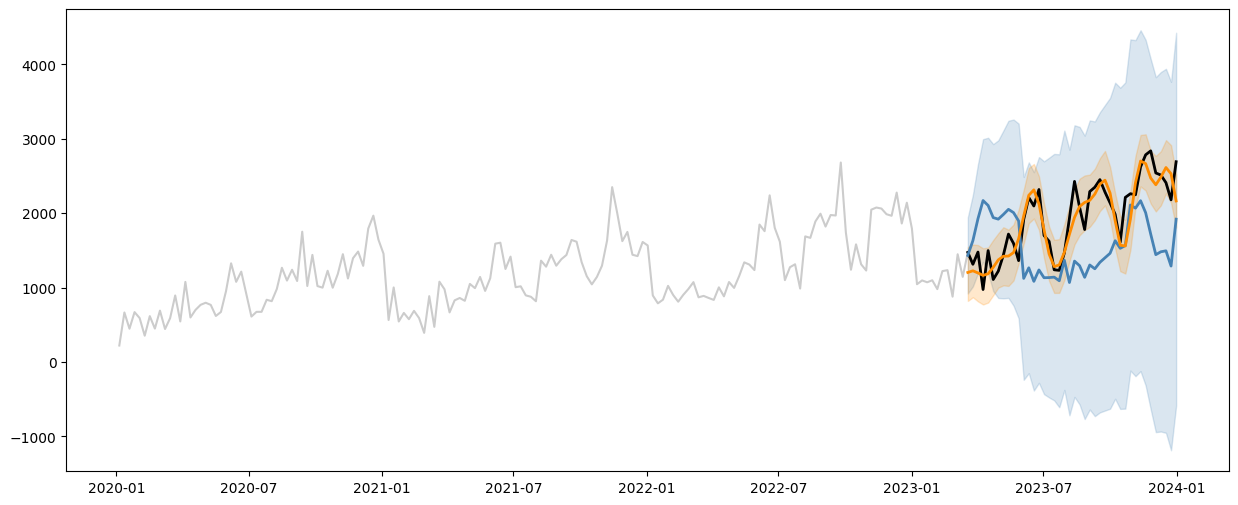

In [9]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(df_weekly_clean['ds'], df_weekly_clean['y'], color='gray', alpha=0.4, label='Full history')
ax.plot(sarima_results['ds'], sarima_results['actual'], color='black', linewidth=2, label='Actual (test)')
ax.plot(sarima_results['ds'], sarima_results['predicted'], color='steelblue', linewidth=2, label='SARIMA forecast')
ax.fill_between(sarima_results['ds'], sarima_results['lower_ci'], sarima_results['upper_ci'],
                 color='steelblue', alpha=0.2, label='SARIMA 95% CI')

ax.plot(prophet_results['ds'], prophet_results['yhat'], color='darkorange', linewidth=2, label='Prophet forecast')
ax.fill_between(prophet_results['ds'], prophet_results['yhat_lower'], prophet_results['yhat_upper'],
                 color='darkorange', alpha=0.2, label='Prophet 95% CI')

ax.axvline(test['ds'].min(), color='red', linestyle='--', linewidth=1, label='Test period starts')
ax.set_title('Actual vs SARIMA vs Prophet — Test Period Forecast', fontsize=14)
ax.set_ylabel('Weekly Quantity Sold')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

#### 5) EXPORT EVAL METRICS

In [ ]:
metrics_summary = pd.DataFrame({
    'model': ['SARIMA', 'Prophet'],
    'MAE': [sarima_mae, prophet_mae],
    'RMSE': [sarima_rmse, prophet_rmse],
    'MAPE': [sarima_mape, prophet_mape],
    'Coverage_Rate_PICP': [sarima_coverage, prophet_coverage],
    'Interval_Width': [sarima_width, prophet_width],
    'Winkler_Score': [sarima_winkler, prophet_winkler],
    'CRPS': [sarima_crps, prophet_crps]
})

metrics_summary.to_csv('model_evaluation_metrics.csv', index=False)
print(metrics_summary.round(2))
print("\nSaved: model_evaluation_metrics.csv — ready for dashboard KPI cards.")